# **SDD Spatial Resolution Fit  |  Crab 2-50 keV**

In [83]:
from pathlib import Path
from typing import Any, NamedTuple, Optional

import numpy as np
from numpy.typing import NDArray
import matplotlib as mpl
import matplotlib.pyplot as plt
from astropy.io.fits import FITS_rec

from bloodmoon.io import simulation_files
from bloodmoon.mask import CodedMaskCamera, codedmask
from bloodmoon.mask import count
from bloodmoon.types import CoordEquatorial
import darksun as ds
from darksun.benchmarking import source_catalogue_data
from darksun.data import DataLoader, CatalogueLoader

plt.rcdefaults()

RCPARAMS = {
    'axes.formatter.limits': (-3, 3),
    'savefig.bbox': 'tight',
}
mpl.rcParams.update(RCPARAMS)

ds.show.set_figures_darkbkg()

In [84]:
class CountListsMap(NamedTuple):
    common: NDArray
    unique: NDArray
    idx_a: NDArray
    idx_b: NDArray

def get_ctsmap_for_lists(
    phlist_A: FITS_rec,
    phlist_B: FITS_rec,
    select_by: str = 'ID',
    uniqueIDs: bool = True,
) -> CountListsMap:
    """
    Finds common count IDs in given photon lists.
    Returns the sorted, unique src IDs that are in both input lists, and the index map.
    """
    ida, idb = phlist_A[select_by], phlist_B[select_by]
    common, idx_a, idx_b = np.intersect1d(ida, idb, assume_unique=uniqueIDs, return_indices=True)
    unique = np.setxor1d(ida, idb, assume_unique=uniqueIDs)
    return CountListsMap(common, unique, idx_a, idx_b)

def get_source_coords(sourceID: str, catalogue: CatalogueLoader) -> CoordEquatorial:
    """Extracts the source RA/Dec coords from catalogue."""
    data = source_catalogue_data(sourceID, catalogue.DLdata)
    return CoordEquatorial(data['RA'], data['DEC'])

def select_target_srcs(
    photons: FITS_rec,
    srcIDs: str | tuple[str, ...],
    catalogue: CatalogueLoader,
) -> FITS_rec:
    """Filters the input photon list for the given sources equatorial coords."""
    srcIDs_ = (srcIDs,) if isinstance(srcIDs, str) else srcIDs
    coords = tuple(get_source_coords(src, catalogue) for src in srcIDs_)
    phs = ds.select_source_photons(coords, photons, False)
    return phs

In [85]:
MASK_FITS: str = "mask_NTHT_20260129_CORRECTED.fits"
SKYFIELD: str = "IROSDummy"
DATA_FITS: str = "baseline_2-50keV_1ks"

ID_CAMERA: str = "cam1a"

E_min: float = 2.0  # [keV]
E_max: float = 50.0  # [keV]

UPS_X, UPS_Y = 5, 2
hide_bulk_els_y: float = 1.5   # [mm]

In [86]:
BASEDIR: str = "/mnt/dbb8f47e-da06-47bf-8ef5-038092af70f7/Edos_Magnificent_Manor/PhD_AASS/Coding/IROS_Data/Simulations"
# BASEDIR: str = "/mnt/d/PhD_AASS/Coding/Images_fits"

DATAPATH: str = f"{BASEDIR}/{SKYFIELD}/{DATA_FITS}/"

In [87]:
wfm: CodedMaskCamera = codedmask(f'{BASEDIR}/{MASK_FITS}', UPS_X, UPS_Y, hide_bulk_els_y=hide_bulk_els_y)

filepaths: dict[str, dict[str, Path]] = simulation_files(DATAPATH)

cat = ds.get_catalogue(filepaths[ID_CAMERA]['sources'])
sdl_detect, sdl_recons = map(
    lambda f: ds.get_data(f, E_min=E_min, E_max=E_max),
    (filepaths[ID_CAMERA]['detected'], filepaths[ID_CAMERA]['reconstructed']),
)

In [88]:
srcID: str = 's10'

phs_detect, phs_recons = map(lambda sdl: np.sort(select_target_srcs(sdl.DLdata, srcID, cat)), (sdl_detect, sdl_recons))
sdd_detect, sdd_recons = map(lambda data: count(wfm, data)[0], (phs_detect, phs_recons))

CATALOG ='IROS_benchmark_catalogue_1ks.fits' / Catalog file                      [astropy.io.fits.card]


UserInfo: using bulk mask of [0.0 x 1.5] mm.


In [89]:
len_detec, len_recons = map(len, (phs_detect, phs_recons))
len_unq_detec, len_unq_recons = map(lambda x: len(np.unique(x)), (phs_detect['ID'], phs_recons['ID']))

print(
    f'Selected source: {srcID} in ({E_min}, {E_max}) keV\n\n'

    f'  * counts from detected list: {len_detec}\n'
    f'  * counts from reconstructed list: {len_recons}\n'
    f'  * delta counts: {len_detec - len_recons} ({(len_detec - len_recons) * 100 / len_detec:.4f} %)\n\n'

    f'  * repetitions in detected list: {len_detec - len_unq_detec} ({(len_detec - len_unq_detec) / len_detec} %)\n'
    f'  * repetitions in reconstructed list: {len_recons - len_unq_recons} ({(len_recons - len_unq_recons) / len_recons} %)'
)

Selected source: s10 in (2.0, 50.0) keV

  * counts from detected list: 61640
  * counts from reconstructed list: 61186
  * delta counts: 454 (0.7365 %)

  * repetitions in detected list: 0 (0.0 %)
  * repetitions in reconstructed list: 0 (0.0 %)


In [90]:
# remove repeted entries in reconstructed list
if len_recons - len_unq_recons > 0:
    _, idxs = np.unique(phs_recons['ID'], return_index=True)
    phs_recons = phs_recons[idxs]

assert len(phs_recons['ID']) == len_unq_recons

## **Visual Inspection**

In [91]:
axis: str = 'Y'

ctsmap = get_ctsmap_for_lists(phs_detect, phs_recons)
y_det, y_rec = phs_detect[axis][ctsmap.idx_a], phs_recons[axis][ctsmap.idx_b]

axflag = axis == 'Y'
mask_eldim = wfm.specs.mask_deltay if axflag else wfm.specs.mask_deltax
mask_pitch = wfm.specs.slit_deltay if axflag else wfm.specs.slit_deltax
bins = wfm.bins_detector.y if axflag else wfm.bins_detector.x

print(f'Analysing {'coarse' if axflag else 'fine'} axis...')

Analysing coarse axis...


In [92]:
def get_artefact_mask(camera: CodedMaskCamera, x: NDArray, bins: NDArray, axis: int = -1, hsdd: bool = False) -> NDArray:
    idxs = (bins[:-1] + bins[1:]) / 2
    if not hsdd:
        idxs = idxs * (camera.bulk.sum(axis=axis) > 0)
    symm_mask = (idxs > 0)
    btm, top = idxs[symm_mask][0] - mask_eldim / 2, idxs[symm_mask][-1] + mask_eldim / 2
    artfct_mask = ((-top <= x) & (x <= -btm)) | ((btm <= x) & (x <= top))
    return artfct_mask

In [93]:
artfct_mask = get_artefact_mask(wfm, y_det, bins, int(axflag))

y_det_flt, y_rec_flt = y_det[artfct_mask], y_rec[artfct_mask]

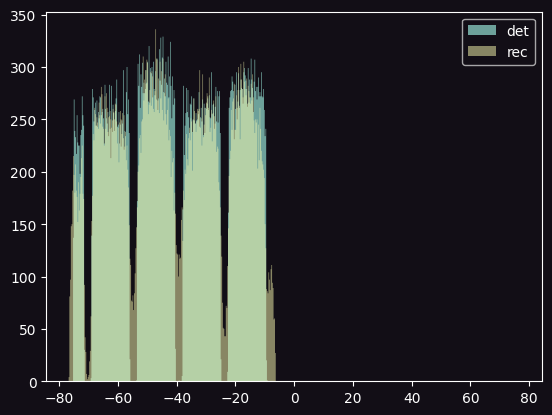

In [94]:
a, *_ = np.histogram(y_det_flt, bins)
b, *_ = np.histogram(y_rec_flt, bins)

_ = plt.stairs(a, bins, label='det', alpha=0.75, fill=True)  # a * artfct_mask
_ = plt.stairs(b, bins, label='rec', alpha=0.5, fill=True)   # b * artfct_mask
_ = plt.legend()

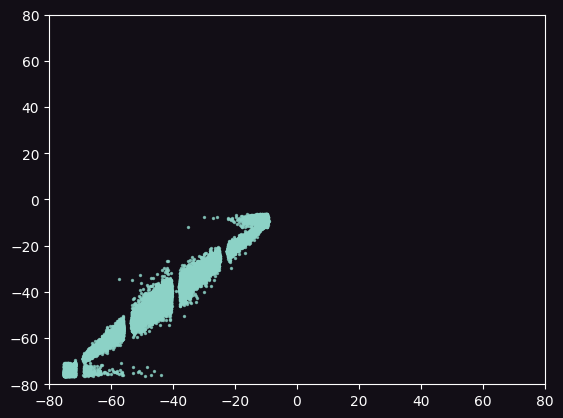

In [95]:
_ = plt.scatter(y_det_flt, y_rec_flt, alpha=0.75, s=2)
_ = plt.ylim((-80, 80))
_ = plt.xlim((-80, 80))

## **Resolution Fit**

In [96]:
from scipy.ndimage import gaussian_filter
from scipy.optimize import curve_fit
from scipy.signal import convolve

def wfm_psfy_kernel(x: NDArray, alpha: float, beta: float, sigma: float) -> NDArray:
    """Returns PSF normalised convolution kernel."""
    gauss_kws = {"mode": 'constant', "cval": 0.0}
    modsec = 1.0 / np.cosh(np.abs(x / alpha) ** beta)
    psfy = gaussian_filter(modsec, sigma, **gauss_kws)
    return psfy / np.sum(psfy)

def apply_detector_resolution(shadowgram: NDArray, kernel: NDArray) -> NDArray:
    """Applies finite detector spatial resolution effects to a shadowgram."""
    return convolve(shadowgram, kernel.reshape(len(kernel), -1), mode="same")

def print_fitres(popt: NDArray, pcov: NDArray, pnames: Optional[tuple[str, ...]] = None) -> NDArray:
    errs = np.sqrt(np.diag(pcov))
    pnames_ = pnames if pnames is not None else [f'p[{idx}]' for idx in range(len(popt))]
    print('Optimised Params:')
    for idx, p in enumerate(popt):
        print(f'  * {pnames_[idx]}: {float(p)} +/- {float(errs[idx])}')
    return

**[First Case] Counts Position Fit**

In [97]:
# NOTE: use of H_SDD returns ASYMMETRIC residuals (hmm...)

# y_det, y_rec = phs_recons['YPHOTON'], phs_recons['Y_HSDD']
# bins = np.arange(0.0, 80.0, mask_eldim)

# artfct_mask = get_artefact_mask(wfm, y_det, bins, hsdd=True)
# y_det_flt, y_rec_flt = y_det[artfct_mask], y_rec[artfct_mask]

In [98]:
els_res = mask_eldim / wfm.upscale_f[int(axflag)]
els_res = 0.1
# grade_mask = (src_rec['GRADE'] > 2)

sddres_bins = np.linspace(-mask_pitch, mask_pitch, 2 * int(mask_pitch / els_res) + 1)
psfy_hist, *_ = np.histogram(y_det_flt - y_rec_flt, sddres_bins)
psfy_hist = psfy_hist / psfy_hist.sum()

print(f'Bins in [{-mask_pitch:.4f}, {mask_pitch:.4f}] mm (# bins: {len(sddres_bins)}), resolution of {els_res:.4f} mm.')

Bins in [-15.5000, 15.5000] mm (# bins: 311), resolution of 0.1000 mm.


In [99]:
popt, pcov = curve_fit(wfm_psfy_kernel, xdata=(sddres_bins[:-1] + sddres_bins[1:]) / 2, ydata=psfy_hist, p0=[0.7, 0.8, 0.1])
print_fitres(popt, pcov, pnames=['alpha', 'beta', 'sigma'])

Optimised Params:
  * alpha: 0.26057442111475865 +/- inf
  * beta: 0.5686036346195624 +/- inf
  * sigma: 0.1 +/- inf


/tmp/ipykernel_17013/3027774881.py:1: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = curve_fit(wfm_psfy_kernel, xdata=(sddres_bins[:-1] + sddres_bins[1:]) / 2, ydata=psfy_hist, p0=[0.7, 0.8, 0.1])


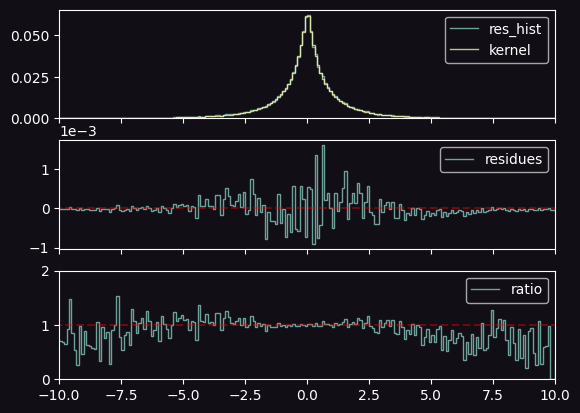

In [100]:
kernel = wfm_psfy_kernel((sddres_bins[:-1] + sddres_bins[1:]) / 2, *popt)
xlim = (-10, 10)

fig, axs = plt.subplots(3, 1, sharex='all')
axs[0].stairs(psfy_hist, edges=sddres_bins, alpha=0.75, label='res_hist')
axs[0].stairs(kernel, edges=sddres_bins, alpha=0.75, label='kernel')
axs[1].stairs(psfy_hist - kernel, edges=sddres_bins, alpha=0.75, label='residues')
axs[1].plot(sddres_bins, np.zeros_like(sddres_bins), 'r--', alpha=0.4)
axs[2].stairs(psfy_hist / kernel, edges=sddres_bins, alpha=0.75, label='ratio')
axs[2].plot(sddres_bins, np.ones_like(sddres_bins), 'r--', alpha=0.4)
axs[2].set_ylim((0.0, 2.0))
for ax in axs:
    ax.set_xlim(xlim)
    ax.legend()

**[Second Case] Shadowgram Fit**

In [101]:
from bloodmoon.coords import equatorial2pos
from bloodmoon.mask import decode, variance
from darksun.benchmarking import crop_source_psf

def fit_psfy_from_detector(
    camera: CodedMaskCamera,
    detected: NDArray,
    reconstructed: NDArray,
    coords: tuple[int, int],
    p0: Optional[list] = None,
    crp_offset: tuple[int, int] = (1, 1),
    bounds: Optional[list[tuple]] = (-np.inf, np.inf),
) -> tuple[NDArray, NDArray]:
    """
    Performs SDD resolution kernel fit along coarse direction by comparing the source
    sky PSFs obtained from corrected 'detected' VS 'reconstructed' shadowgrams.
    """
    nsteps = 2 * int(camera.specs.slit_deltay * camera.upscale_f.y / camera.specs.mask_deltay) + 1
    bins = np.linspace(-camera.specs.slit_deltay, camera.specs.slit_deltay, nsteps)
    sky_recons = decode(camera, reconstructed)
    rows, cols = crop_source_psf(camera, coords, *crp_offset)
    src_psf = sky_recons[rows, cols] + 1

    varmap = variance(camera, reconstructed)
    psfvar = varmap[rows, cols]

    def model(x: NDArray, alpha: float, beta: float, sigma: float) -> tuple[NDArray, NDArray]:
        kernel = wfm_psfy_kernel(bins, alpha, beta, sigma)
        corr = apply_detector_resolution(detected, kernel)
        sky = decode(camera, corr)
        return sky[rows, cols].flatten() + 1

    ydata = src_psf.flatten()
    sigma = np.pow(np.clip(psfvar, a_min=1.0, a_max=None), -0.5).flatten()
    lsq_factory = dict(
        jac='3-point',
        ftol=1e-8,
        xtol=1e-8,
        x_scale='jac',
        loss='linear',
    )
    popt, pcov = curve_fit(
        f=model,
        xdata=np.arange(len(ydata)),
        ydata=ydata,
        p0=p0,
        sigma=sigma,
        bounds=bounds,
        method='trf',
        **lsq_factory,
    )

    return popt, pcov

In [102]:
def find_tick_val(ticks: NDArray, trg_vals: NDArray, atol: float = 1e-4) -> NDArray:
    """Finds the idxs inside `ticks` relative to given values `trg_vals`."""
    trg_idxs: list[int] = []
    for v in trg_vals:
        idx = np.argwhere(np.isclose(ticks, v, atol=atol))
        if idx.size > 0: trg_idxs.append(idx[0, 0])
    return np.array(trg_idxs)

def set_phase(x: NDArray) -> NDArray:
    """Centers `x` values around zero."""
    return np.arange(len(x) + 1) - len(x) // 2 - 0.5

def get_slices(*arrs: NDArray) -> tuple[tuple[NDArray, ...], tuple[NDArray, ...]]:
    n, m = arrs[0].shape
    xslice, yslice = zip(*tuple((c[(n - 1) // 2, :], c[:, (m - 1) // 2]) for c in arrs))
    return xslice, yslice

def get_heatmap_plot_data(
    psf: NDArray,
    psf_err: NDArray,
    modelled: NDArray,
    modelled_err: NDArray,
    mode: str,
    express_res_perc: bool,
) -> tuple[NDArray, str]:
    """Handles source PSF residuals heatmap to plot."""
    if mode == 'ratio':
        return psf / modelled, 'ratio'

    res = psf - modelled
    if mode == 'res':
        lbl = 'residuals [ph]'
        if express_res_perc:
            res = res * 100 / psf.max()
            lbl = r'residuals [%]'
        return res, lbl

    sigma = np.sqrt(np.square(psf_err) + np.square(modelled_err))
    return res / sigma, 'residuals [$\\sigma$]'

def get_slices_plot_data(
    psf: NDArray,
    psf_err: NDArray,
    modelled: NDArray,
    modelled_err: NDArray,
    mode: str,
    express_res_perc: bool,
    n_sigma: int,
) -> tuple[NDArray, NDArray, str]:
    """
    Handles data to plot from source PSF and sigma slices, for both true and modelled.
    """
    if mode not in ('res', 'ratio', 'sigma'):
        raise ValueError(f"Invalid input mode '{mode}'.")
    
    if mode == 'ratio':
        sigma = psf_err / np.abs(modelled) + np.abs(psf / np.square(modelled)) * modelled_err
        return psf / modelled, n_sigma * sigma, 'ratio'

    res = psf - modelled
    sigma = np.sqrt(np.square(psf_err) + np.square(modelled_err))

    if mode == 'res':
        lbl = 'residuals [counts]'
        if express_res_perc:
            res, sigma = map(lambda x: x * 100 / psf.max(), (res, sigma))
            lbl = r'residuals [%]'
        return res, n_sigma * sigma, lbl

    return res / sigma, n_sigma * np.ones_like(res), 'residuals [$\\sigma$]'

def show_PSF_total(
    camera: CodedMaskCamera,
    true_w_err: tuple[NDArray, NDArray],
    modelled_w_err: tuple[NDArray, NDArray],
    save_to: str | None = None,
    express_res_perc: bool = True,
    express_res_sigma: bool = False,
    n_sigma: int = 1,
    cts_lims: tuple = (None, None),
    hm_ratio_lims: tuple = (None, None),
    fine_ratio_lims: tuple = (None, None),
    coarse_ratio_lims: tuple = (None, None),
    save_options: dict[str, Any] | None = None,
    **fig_kws,
) -> None:
    """
    Plots the source PSF heat maps and profiles along fine/coarse axes + cfr with modelled source.
    """
    res_mode = 'res'
    if express_res_sigma:
        express_res_perc = False
        res_mode = 'sigma'

    title_fs = 16
    lbl_fs = 14
    
    dtx, dty = ds.pixels_angular_resolution(camera, verbose=False)
    psf, modelled = true_w_err[0], modelled_w_err[0]
    psf_xslice, psf_yslice = get_slices(*true_w_err)
    modelled_xslice, modelled_yslice = get_slices(*modelled_w_err)

    phase_fine, phase_coarse = (
        dtx * set_phase(psf_xslice[0]),
        dty * set_phase(psf_yslice[0]) / 60,
    )
    phase_ferr, phase_cerr = (
        dtx * (set_phase(psf_xslice[0])[:-1] + 0.5),
        dty * (set_phase(psf_yslice[0])[:-1] + 0.5) / 60,
    )
    
    slice_clrs = ('OrangeRed', 'DodgerBlue')
    img_factory = dict(origin='lower', interpolation='none', aspect=2 * psf.shape[1] / psf.shape[0])
    errbar_factory = dict(linestyle='', elinewidth=0.7, capsize=0)

    fig, axs = plt.subplots(3, 3, tight_layout=True, **fig_kws)
    axs = axs.flatten()

    # ------------------------ 1st ROW (PSF HM + Profiles f/c) ---------------------------
    slice_lim_vals = max(modelled.max(), psf.max())
    slice_lim_vals = (cts_lims[0] or -0.075 * slice_lim_vals, cts_lims[1] or 1.05 * slice_lim_vals)
    
    axs[0].set_title('Crab PSF', fontsize=title_fs)
    psf_img = axs[0].imshow(psf, cmap='gist_heat', vmin=cts_lims[0], vmax=cts_lims[1], **img_factory)
    cbar = fig.colorbar(psf_img, ax=axs[0], location='right', shrink=0.8, pad=0.05)
    cbar.set_label('counts', fontsize=lbl_fs)
    cbar.ax.tick_params(labelsize=lbl_fs)
    axs[0].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]', fontsize=lbl_fs)
    axs[0].set_ylabel(ylabel='$\\Delta\\theta_{coarse}$ [deg]', fontsize=lbl_fs)

    axs[1].set_title('PSF Slice - Fine Axis', fontsize=title_fs)
    axs[1].stairs(psf_xslice[0], edges=phase_fine, edgecolor=slice_clrs[0], label='true')
    axs[1].stairs(modelled_xslice[0], edges=phase_fine, edgecolor=slice_clrs[1], label='modelled')
    axs[1].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]', fontsize=lbl_fs)

    axs[2].set_title('PSF Slice - Coarse Axis', fontsize=title_fs)
    axs[2].stairs(psf_yslice[0], edges=phase_coarse, edgecolor=slice_clrs[0], label='true')
    axs[2].stairs(modelled_yslice[0], edges=phase_coarse, edgecolor=slice_clrs[1], label='modelled')
    axs[2].set_xlabel(xlabel='$\\Delta\\theta_{coarse}$ [deg]', fontsize=lbl_fs)
    axs[2].set_ylabel(ylabel='counts', labelpad=10, fontsize=lbl_fs)

    for idx in [1, 2]: axs[idx].set_ylim(slice_lim_vals)

    # ------------------------ 2nd ROW (RES [%] HM + Profiles f/c) ------------------------    
    psf_hm_res, hm_lbl = get_heatmap_plot_data(*true_w_err, *modelled_w_err, res_mode, express_res_perc)
    xres, xsigma, lbl = get_slices_plot_data(*psf_xslice, *modelled_xslice, res_mode, express_res_perc, n_sigma)
    yres, ysigma, _ = get_slices_plot_data(*psf_yslice, *modelled_yslice, res_mode, express_res_perc, n_sigma)

    axs[3].set_title(f'Crab PSF Residuals', fontsize=title_fs)
    mod_img = axs[3].imshow(psf_hm_res, **img_factory)
    cbar = fig.colorbar(mod_img, ax=axs[3], location='right', shrink=0.8, pad=0.05)
    cbar.set_label(hm_lbl, fontsize=lbl_fs)
    cbar.ax.tick_params(labelsize=lbl_fs)
    axs[3].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]', fontsize=lbl_fs)
    axs[3].set_ylabel(ylabel='$\\Delta\\theta_{coarse}$ [deg]', fontsize=lbl_fs)

    axs[4].set_title(f'PSF Slice Residuals - Fine Axis', fontsize=title_fs)
    axs[4].plot(phase_fine, np.zeros_like(phase_fine), slice_clrs[0], label='ground', linestyle='--', alpha=0.6)
    axs[4].stairs(xres, edges=phase_fine, edgecolor=slice_clrs[1], label=lbl)
    axs[4].errorbar(phase_ferr, xres, c=slice_clrs[1], yerr=xsigma, marker='', **errbar_factory)
    axs[4].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]', fontsize=lbl_fs)

    axs[5].set_title(f'PSF Slice Residuals - Coarse Axis', fontsize=title_fs)
    axs[5].plot(phase_coarse, np.zeros_like(phase_coarse), slice_clrs[0], label='ground', linestyle='--', alpha=0.6)
    axs[5].stairs(yres, edges=phase_coarse, edgecolor=slice_clrs[1], label=lbl)
    axs[5].errorbar(phase_cerr, yres, c=slice_clrs[1], yerr=ysigma, marker='', **errbar_factory)
    axs[5].set_xlabel(xlabel='$\\Delta\\theta_{coarse}$ [deg]', fontsize=lbl_fs)
    axs[5].set_ylabel(ylabel=lbl + f" (C.L. ${n_sigma}\\sigma$)", labelpad=10, fontsize=lbl_fs)

    # ------------------------ 3rd ROW (RATIO HM + Profiles f/c) --------------------------
    psf_hm_res, hm_lbl = get_heatmap_plot_data(*true_w_err, *modelled_w_err, 'ratio', express_res_perc)
    xres, xsigma, lbl = get_slices_plot_data(*psf_xslice, *modelled_xslice, 'ratio', express_res_perc, n_sigma)
    yres, ysigma, _ = get_slices_plot_data(*psf_yslice, *modelled_yslice, 'ratio', express_res_perc, n_sigma)

    vlim = max(np.abs(xres).max(), np.abs(yres).max())
    hm_res_lims_ = (hm_ratio_lims[0] or -vlim + 1, hm_ratio_lims[1] or vlim + 1)

    axs[6].set_title(f'Crab PSF Ratio', fontsize=title_fs)
    mod_img = axs[6].imshow(psf_hm_res, vmin=hm_res_lims_[0], vmax=hm_res_lims_[1], **img_factory)
    cbar = fig.colorbar(mod_img, ax=axs[6], location='right', shrink=0.8, pad=0.05)
    cbar.set_label(hm_lbl, fontsize=lbl_fs)
    cbar.ax.tick_params(labelsize=lbl_fs)
    axs[6].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]', fontsize=lbl_fs)
    axs[6].set_ylabel(ylabel='$\\Delta\\theta_{coarse}$ [deg]', fontsize=lbl_fs)

    axs[7].set_title(f'PSF Slice Ratio - Fine Axis', fontsize=title_fs)
    axs[7].plot(phase_fine, np.ones_like(phase_fine), slice_clrs[0], label='ground', linestyle='--', alpha=0.6)
    axs[7].stairs(xres, edges=phase_fine, edgecolor=slice_clrs[1], label=lbl)
    axs[7].errorbar(phase_ferr, xres, c=slice_clrs[1], yerr=xsigma, marker='', **errbar_factory)
    axs[7].set_ylim(fine_ratio_lims)
    axs[7].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]', fontsize=lbl_fs)

    axs[8].set_title(f'PSF Slice Ratio - Coarse Axis', fontsize=title_fs)
    axs[8].plot(phase_coarse, np.ones_like(phase_coarse), slice_clrs[0], label='ground', linestyle='--', alpha=0.6)
    axs[8].stairs(yres, edges=phase_coarse, edgecolor=slice_clrs[1], label=lbl)
    axs[8].errorbar(phase_cerr, yres, c=slice_clrs[1], yerr=ysigma, marker='', **errbar_factory)
    axs[8].set_ylim(coarse_ratio_lims)
    axs[8].set_xlabel(xlabel='$\\Delta\\theta_{coarse}$ [deg]', fontsize=lbl_fs)
    axs[8].set_ylabel(ylabel=lbl + f" (C.L. ${n_sigma}\\sigma$)", labelpad=10, fontsize=lbl_fs)

    # ticks for HMs
    yticks, xticks = map(lambda s: np.arange(0, s), psf.shape)
    _ytick_lbls, _xtick_lbls = (
        dty / 60 * (yticks - len(yticks) // 2), dtx * (xticks - len(xticks) // 2),
    )
    yticks_ = find_tick_val(_ytick_lbls, np.array([-5.0, -2.5, 0.0, 2.5, 5.0]), atol=7e-2)
    yticks_lbl = [float(f'{t:.1f}') for t in _ytick_lbls[yticks_]]
    xticks_ = find_tick_val(_xtick_lbls, np.array([-5.0, 0.0, 5.0]), atol=1e-1)
    xticks_lbl = [float(f'{t:.1f}') for t in _xtick_lbls[xticks_]]

    for idx in [0, 3, 6]:
        axs[idx].set_xticks(xticks_, xticks_lbl)
        axs[idx].set_yticks(yticks_, yticks_lbl)
    
    for idx in [1, 2, 4, 5, 7, 8]:
        axs[idx].yaxis.tick_right()
        axs[idx].legend(loc='best')

    for idx in [2, 5, 8]:
        axs[idx].yaxis.set_label_position('right')

    for idx, ax in enumerate(axs):
        ax.xaxis.set_ticks_position('both')
        ax.yaxis.set_ticks_position('both')
        ax.tick_params(which='both', direction='in', width=1.5, length=4 if 'major' else 2.5, labelsize=lbl_fs)

    if save_to is not None:
        save_options_ = save_options or {}
        fig.savefig(save_to, **save_options_)
    
    plt.show()
    return

def inspect_src(
    camera: CodedMaskCamera,
    detected: NDArray,
    reconstructed: NDArray,
    coords: tuple[int, int],
    kernel_popt: NDArray,
    save_to: Optional[str] = None,
    **kwargs,
) -> None:
    nsteps = 2 * int(camera.specs.slit_deltay * camera.upscale_f.y / camera.specs.mask_deltay) + 1
    bins = np.linspace(-camera.specs.slit_deltay, camera.specs.slit_deltay, nsteps)
    rows, cols = crop_source_psf(camera, coords, wfm.upscale_f.x + 1, wfm.upscale_f.y + 5)

    kernel = wfm_psfy_kernel(bins, *kernel_popt)
    corr = apply_detector_resolution(detected, kernel)

    sky_popt, sky_recons = decode(wfm, corr), decode(wfm, reconstructed)
    psf_popt, psf_recons = sky_popt[rows, cols], sky_recons[rows, cols]

    varmap = variance(camera, reconstructed)
    psf_var = varmap[rows, cols]

    show_PSF_total(
        camera=camera,
        true_w_err=(psf_recons, np.sqrt(psf_var)),
        modelled_w_err=(psf_popt, np.zeros_like(psf_popt)),  # NOTE: [validate sg error consistency] np.sqrt(psf_model_var)
        save_to=save_to,
        **kwargs,
    )
    return

In [103]:
wfm_img: CodedMaskCamera = codedmask(f'{BASEDIR}/{MASK_FITS}', 5, 2, hide_bulk_els_y=hide_bulk_els_y)
coords = equatorial2pos(sdl_recons, wfm_img, *get_source_coords(srcID, cat))

popt_img, pcov_img = fit_psfy_from_detector(
    camera=wfm_img,
    detected=sdd_detect,
    reconstructed=sdd_recons,
    coords=coords,
    p0=[0.7, 0.8, 0.1],
    crp_offset=(3, 5),
)
print_fitres(popt_img, pcov_img, pnames=['alpha', 'beta', 'sigma'])

UserInfo: using bulk mask of [0.0 x 1.5] mm.
Optimised Params:
  * alpha: 0.13154570771067542 +/- 0.014203733328384685
  * beta: 0.4627524404382487 +/- 0.011176206767607406
  * sigma: 0.1 +/- 0.0


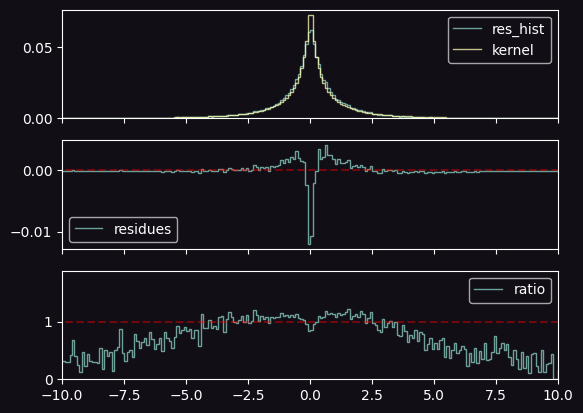

In [104]:
kernel_img = wfm_psfy_kernel((sddres_bins[:-1] + sddres_bins[1:]) / 2, *popt_img)
xlim = (-10, 10)

fig, axs = plt.subplots(3, 1, sharex='all')
axs[0].stairs(psfy_hist, edges=sddres_bins, alpha=0.75, label='res_hist')
axs[0].stairs(kernel_img, edges=sddres_bins, alpha=0.75, label='kernel')
axs[1].stairs(psfy_hist - kernel_img, edges=sddres_bins, alpha=0.75, label='residues')
axs[1].plot(sddres_bins, np.zeros_like(sddres_bins), 'r--', alpha=0.4)
axs[2].stairs(psfy_hist / kernel_img, edges=sddres_bins, alpha=0.75, label='ratio')
axs[2].plot(sddres_bins, np.ones_like(sddres_bins), 'r--', alpha=0.4)
for ax in axs:
    ax.set_xlim(xlim)
    ax.legend()

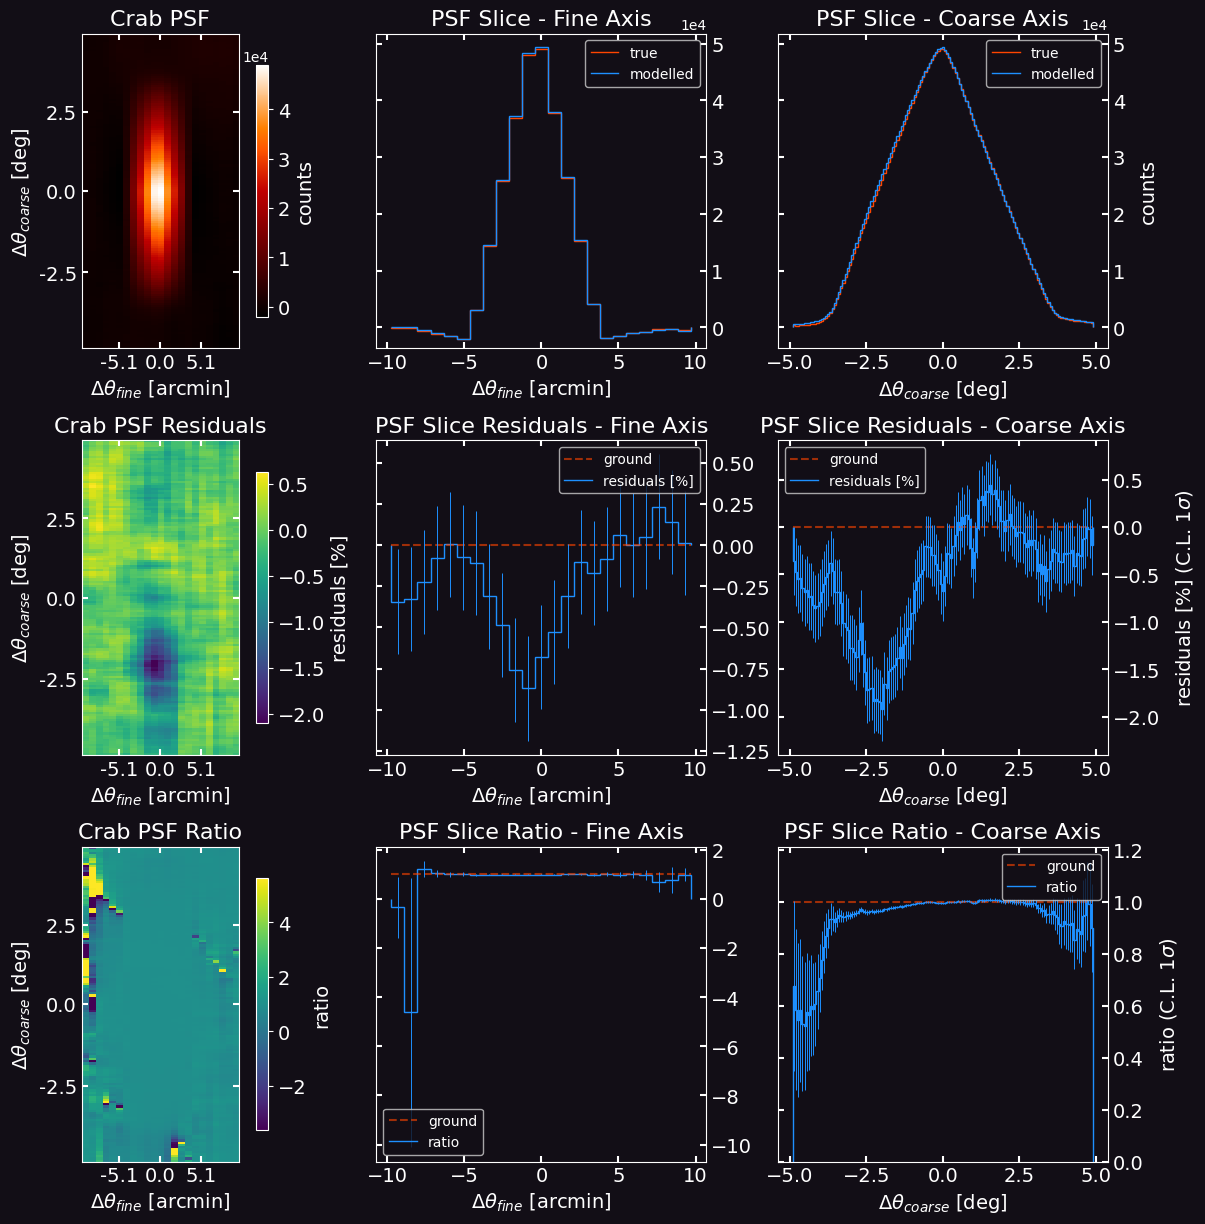

In [107]:
inspect_src(
    camera=wfm_img,
    detected=sdd_detect,
    reconstructed=sdd_recons,
    coords=coords,
    kernel_popt=popt_img,
    figsize=(4 * 3 + 0.5, 4 * 3 + 0.5),
)